# 05 – Support Vector Machine (RBF kernel)
**Mock Data Science Challenge – Dataset A** · Model notebook owned by **Person 5** _<name>_

This notebook is **standalone**: it loads the data, applies the shared pre-processing and metric, then tunes, evaluates and explains **Support Vector Machine (RBF kernel)**.
At the end it saves a results file and test predictions for `06_Final_Cost_Comparison`.

**Outline:** 1–4 shared setup · 5 Model and pre-processing comparison · 6 Hyper-parameter tuning · 7 Cost vs threshold ·
8 Repeated cross-validation · 9 Hold-out validation · 10 Explaining the model · 11 Save results and test predictions

## 1. Setup
> 🔒 **Sections 1–4 are identical in every model notebook. Do not change them.** Using the same features, metric, split and folds is what makes the five models comparable in `06_Final_Cost_Comparison`.

In [1]:
# Core libraries
import os, json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# scikit-learn tools shared by all model notebooks
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, log_loss, confusion_matrix
from sklearn.inspection import permutation_importance

In [3]:
RANDOM_STATE = 42
TARGET = 'seasonal_vaccine'
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')

## 2. Load the data

In [4]:
TRAIN_PATH, TEST_PATH = 'dataset_A_training.csv', 'dataset_A_testing.csv'

# In Colab, upload the two CSV files if they are not already in the working folder
if not (os.path.exists(TRAIN_PATH) and os.path.exists(TEST_PATH)):
    from google.colab import files
    files.upload()

In [5]:
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print('Train:', train.shape, ' Test:', test.shape)

Train: (4756, 31)  Test: (4749, 30)


## 3. Features and evaluation metric (from notebook 00)

In [6]:
BINARY = ['behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask',
          'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home',
          'behavioral_touch_face', 'doctor_recc_seasonal', 'child_under_6_months',
          'health_worker', 'health_insurance']
ORDINAL_NUM = ['flu_concern', 'flu_knowledge', 'opinion_seas_vacc_effective',
               'opinion_seas_risk', 'opinion_seas_sick_from_vacc',
               'household_adults', 'household_children', 'number_chronic_med_conditions']

In [7]:
ORDERED_CAT = {
    'age_group': ['18 - 34 Years', '35 - 44 Years', '45 - 54 Years', '55 - 64 Years', '65+ Years'],
    'education': ['< 12 Years', '12 Years', 'Some College', 'College Graduate'],
    'income_poverty': ['Below Poverty', '<= $75,000, Above Poverty', '> $75,000'],
}
NOMINAL = ['race', 'sex', 'marital_status', 'rent_or_own', 'employment_status',
           'census_msa', 'employment_sector']
FEATURES = BINARY + ORDINAL_NUM + list(ORDERED_CAT) + NOMINAL

**Metric (derived in notebook 00).** Predicting 1 ("already vaccinated") for someone who is not means they are not offered a vaccine and risk
hospitalisation (FP = \$18,500). Predicting 0 for someone who is already vaccinated wastes a vaccine (FN = \$300).
We predict 1 only when $p > 18{,}500 / 18{,}800 \approx 0.984$.

In [8]:
COSTS = {'TP': 0, 'TN': 0, 'FP': 18_500, 'FN': 300}

def total_cost(y_true, y_pred, costs=COSTS):
    """Total $ cost of a set of 0/1 predictions."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp * costs['TP'] + tn * costs['TN'] + fp * costs['FP'] + fn * costs['FN']

In [9]:
def cost_per_person(y_true, y_pred, costs=COSTS):
    """Average cost per respondent."""
    return total_cost(y_true, y_pred, costs) / len(y_true)

def bayes_threshold(costs=COSTS):
    """Probability above which predicting 1 is cheaper than predicting 0."""
    a, b = costs['FP'] - costs['TN'], costs['FN'] - costs['TP']
    return a / (a + b)

THRESHOLD = bayes_threshold()
print(f'Cost-optimal threshold: {THRESHOLD:.4f}')

Cost-optimal threshold: 0.9840


## 4. Pre-processing, hold-out split and cross-validation
- **Option A – simple:** median / most-frequent imputation, one-hot encoding, `employment_sector` dropped.
- **Option B – missing-aware:** missing-value indicators, ordered categories as ranks, missing nominal values as their own category `'Missing'`.

In [10]:
prep_A = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), BINARY + ORDINAL_NUM),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]),
     list(ORDERED_CAT) + [c for c in NOMINAL if c != 'employment_sector']),
])

In [11]:
ordinal_pipe = Pipeline([
    ('encode', OrdinalEncoder(categories=list(ORDERED_CAT.values()),
                              handle_unknown='use_encoded_value', unknown_value=np.nan,
                              encoded_missing_value=np.nan)),
    ('impute', SimpleImputer(strategy='median', add_indicator=True)),
    ('scale', StandardScaler()),
])

In [12]:
prep_B = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())]), BINARY + ORDINAL_NUM),
    ('ord', ordinal_pipe, list(ORDERED_CAT)),
    ('nom', Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='Missing')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), NOMINAL),
])

In [13]:
# 80% development set (tuning + CV) / 20% hold-out set (final unseen check)
X, y = train[FEATURES], train[TARGET]
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

In [14]:
def make_pipe(prep, model):
    """Pre-processor + model, so pre-processing is learnt inside each CV fold (no leakage)."""
    return Pipeline([('prep', clone(prep)), ('model', model)])

def evaluate_cv(model, X, y, cv=CV, threshold=THRESHOLD):
    """Per-fold cost per person, AUC and log loss on the validation folds."""
    rows = []
    for tr_idx, va_idx in cv.split(X, y):
        m = clone(model).fit(X.iloc[tr_idx], y.iloc[tr_idx])
        p = m.predict_proba(X.iloc[va_idx])[:, 1]
        y_va = y.iloc[va_idx]
        rows.append({'cost_pp': cost_per_person(y_va, (p >= threshold).astype(int)),
                     'auc': roc_auc_score(y_va, p), 'log_loss': log_loss(y_va, p, labels=[0, 1])})
    return pd.DataFrame(rows)

In [15]:
# Baseline to beat: predict everyone as 0 (offer everyone a vaccine)
BASELINE_PP = cost_per_person(y_dev, np.zeros(len(y_dev)))
print(f'Baseline cost per person (development set): ${BASELINE_PP:.2f}')

Baseline cost per person (development set): $160.88


## 5. Support Vector Machine (RBF kernel)
### Why this model
A support vector machine with an RBF kernel finds a flexible, maximum-margin boundary between vaccinated and unvaccinated respondents.
SVMs do not output probabilities directly, so `probability=True` uses **Platt scaling**: a logistic curve fitted on internal cross-validation folds
that turns SVM scores into probabilities. `C` controls the margin softness and `gamma` controls how flexible the boundary is.

In [16]:
from sklearn.svm import SVC

MODEL_NAME = 'SVM'
base_model = SVC(probability=True, random_state=RANDOM_STATE)

### 5.1 Pre-processing option A vs option B
Untuned model, 5-fold CV on the development set.

In [17]:
prep_results = []
for prep_name, prep in {'A_simple': prep_A, 'B_missing_aware': prep_B}.items():
    res = evaluate_cv(make_pipe(prep, base_model), X_dev, y_dev)
    res['prep'] = prep_name
    prep_results.append(res)
prep_results = pd.concat(prep_results, ignore_index=True)

In [18]:
prep_results.groupby('prep').agg(['mean', 'std']).round(4)

cost_pp             auc         log_loss        
                     mean     std    mean     std     mean     std
prep                                                              
A_simple         160.7255  0.1748  0.8381  0.0105   0.4975  0.0142
B_missing_aware  160.8833  0.0946  0.8432  0.0113   0.4906  0.0156

In [19]:
# Choose the option with the lower log loss (better probabilities) for tuning
prep_ll = prep_results.groupby('prep')['log_loss'].mean()
BEST_PREP_NAME = prep_ll.idxmin()
best_prep = {'A_simple': prep_A, 'B_missing_aware': prep_B}[BEST_PREP_NAME]
print('Pre-processing used from here on:', BEST_PREP_NAME)

Pre-processing used from here on: B_missing_aware


## 6. Hyper-parameter tuning
`RandomizedSearchCV` with 5-fold CV, scored on **log loss**. Log loss is a smooth measure of probability quality, and the cost decision depends on
reliable probabilities. Cost itself only changes when a respondent crosses the 0.984 threshold, so it is too noisy to tune on directly.

In [20]:
param_grid = {'model__C': [0.1, 0.3, 1, 3],
        'model__gamma': ['scale', 0.003, 0.01, 0.03]}

In [21]:
search = RandomizedSearchCV(make_pipe(best_prep, base_model), param_grid, n_iter=15,
                            cv=CV, scoring='neg_log_loss', random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_dev, y_dev)
tuned_model = search.best_estimator_
print('Best CV log loss:', round(-search.best_score_, 4))
print('Best parameters:', search.best_params_)

Best CV log loss: 0.4875
Best parameters: {'model__gamma': 0.003, 'model__C': 3}


In [22]:
# Top 5 parameter combinations tried
cv_res = pd.DataFrame(search.cv_results_)
cv_res['log_loss'] = -cv_res['mean_test_score']
cv_res.sort_values('log_loss')[['params', 'log_loss', 'std_test_score']].head(5)

,params,log_loss,std_test_score
4,"{'model__gamma': 0.003, 'model__C': 3}",0.487544,0.011434
12,"{'model__gamma': 0.01, 'model__C': 1}",0.487844,0.012236
3,"{'model__gamma': 0.01, 'model__C': 3}",0.489999,0.013492
6,"{'model__gamma': 'scale', 'model__C': 1}",0.490563,0.013912
7,"{'model__gamma': 0.003, 'model__C': 1}",0.490676,0.013159


## 7. Cost against decision threshold
Out-of-fold probabilities (each respondent is predicted by a model that did not train on them), then the cost of every threshold.

In [23]:
oof = cross_val_predict(tuned_model, X_dev, y_dev, cv=CV, method='predict_proba')[:, 1]
thresholds = np.linspace(0.80, 1.0, 201)
oof_costs = [cost_per_person(y_dev, (oof >= t).astype(int)) for t in thresholds]
print(f'OOF AUC {roc_auc_score(y_dev, oof):.4f} | OOF log loss {log_loss(y_dev, oof):.4f}')

OOF AUC 0.8466 | OOF log loss 0.4875


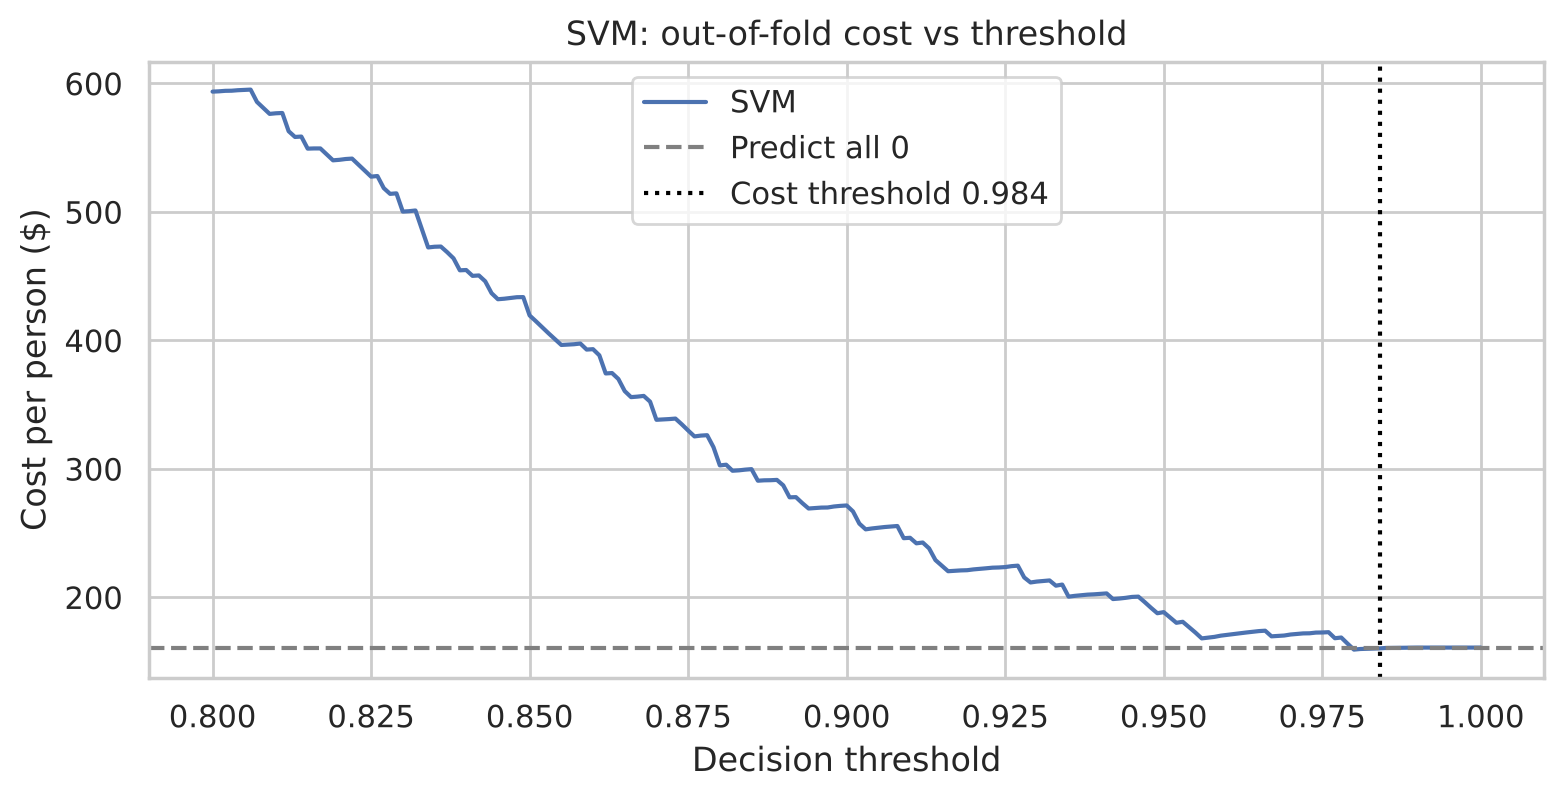

In [24]:
plt.figure(figsize=(9, 4))
plt.plot(thresholds, oof_costs, label=MODEL_NAME)
plt.axhline(BASELINE_PP, ls='--', c='grey', label='Predict all 0')
plt.axvline(THRESHOLD, ls=':', c='black', label=f'Cost threshold {THRESHOLD:.3f}')
plt.xlabel('Decision threshold'); plt.ylabel('Cost per person ($)')
plt.title(f'{MODEL_NAME}: out-of-fold cost vs threshold'); plt.legend(); plt.show()

In [25]:
# Respondents above the cost threshold, and how many of them are really vaccinated
sure = oof >= THRESHOLD
print(f'Predicted 1: {sure.sum()} of {len(oof)}')
if sure.any():
    print(f'Share truly vaccinated among them: {y_dev[sure].mean():.3f}  (needs to be above {THRESHOLD:.3f})')
print(f'OOF cost per person: ${cost_per_person(y_dev, sure.astype(int)):.2f}  vs baseline ${BASELINE_PP:.2f}')

Predicted 1: 7 of 3804
Share truly vaccinated among them: 1.000  (needs to be above 0.984)
OOF cost per person: $160.33  vs baseline $160.88


## 8. Repeated cross-validation (robustness)
5-fold CV repeated 3 times (15 fits) at the cost threshold, to measure how much the cost varies from one data split to another.

In [26]:
rcv = evaluate_cv(tuned_model, X_dev, y_dev, cv=RCV)
baseline_folds = [cost_per_person(y_dev.iloc[va], np.zeros(len(va))) for _, va in RCV.split(X_dev, y_dev)]
rcv['baseline_pp'] = baseline_folds
rcv['saving_pp'] = rcv['baseline_pp'] - rcv['cost_pp']
rcv.describe().loc[['mean', 'std', 'min', 'max']].round(3)

,cost_pp,auc,log_loss,baseline_pp,saving_pp
mean,160.252,0.848,0.487,160.883,0.631
std,0.519,0.015,0.020,0.088,0.490
min,159.264,0.828,0.432,160.841,0.000
max,161.053,0.890,0.514,161.053,1.577


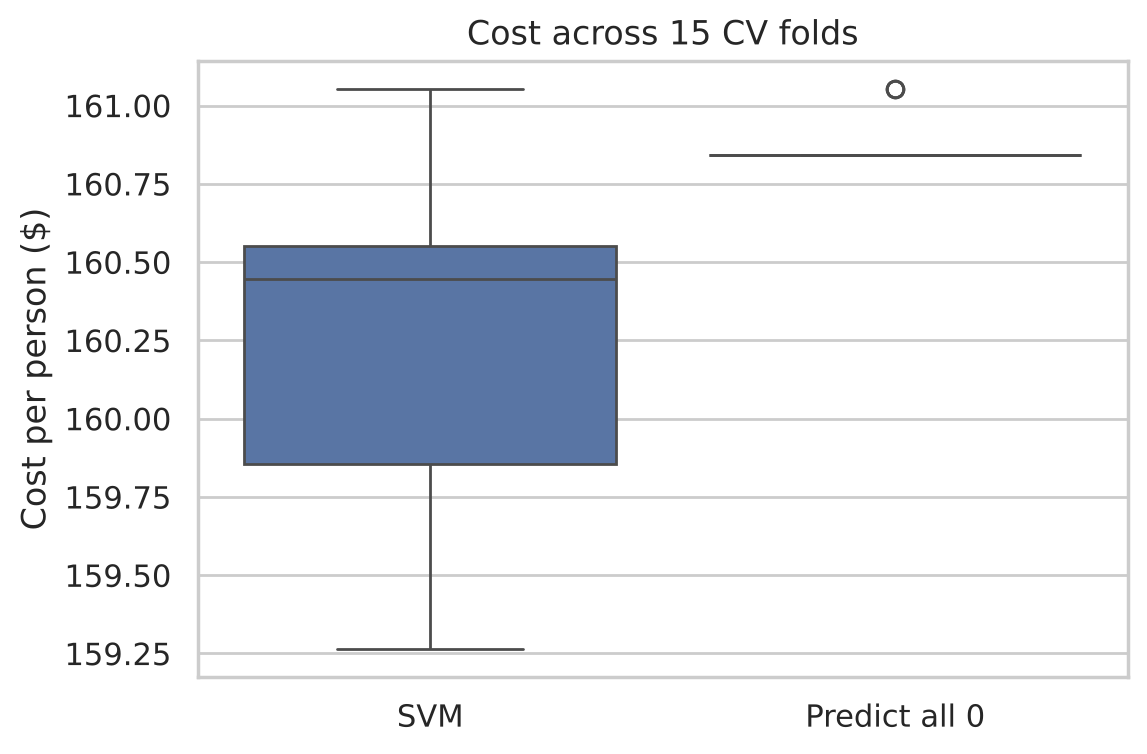

In [27]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=rcv[['cost_pp', 'baseline_pp']].rename(
    columns={'cost_pp': MODEL_NAME, 'baseline_pp': 'Predict all 0'}))
plt.ylabel('Cost per person ($)'); plt.title('Cost across 15 CV folds'); plt.show()

In [28]:
print(f'Mean saving vs baseline: ${rcv.saving_pp.mean():.2f} per person '
      f'(folds where the model beats or matches the baseline: {(rcv.saving_pp >= 0).mean():.0%})')

Mean saving vs baseline: $0.63 per person (folds where the model beats or matches the baseline: 100%)


## 9. Hold-out validation (unseen data)
Fit on the full development set and score once on the 20% hold-out set.

In [29]:
dev_model = clone(tuned_model).fit(X_dev, y_dev)
p_hold = dev_model.predict_proba(X_hold)[:, 1]
pred_hold = (p_hold >= THRESHOLD).astype(int)
hold_baseline = cost_per_person(y_hold, np.zeros(len(y_hold)))

In [30]:
print(f'Hold-out AUC: {roc_auc_score(y_hold, p_hold):.4f}')
print(f'Hold-out cost per person: ${cost_per_person(y_hold, pred_hold):.2f}  (baseline ${hold_baseline:.2f})')
print(f'Hold-out total cost: ${total_cost(y_hold, pred_hold):,}   predicted 1: {pred_hold.sum()}')

Hold-out AUC: 0.8499
Hold-out cost per person: $160.40  (baseline $161.03)
Hold-out total cost: $152,700   predicted 1: 2


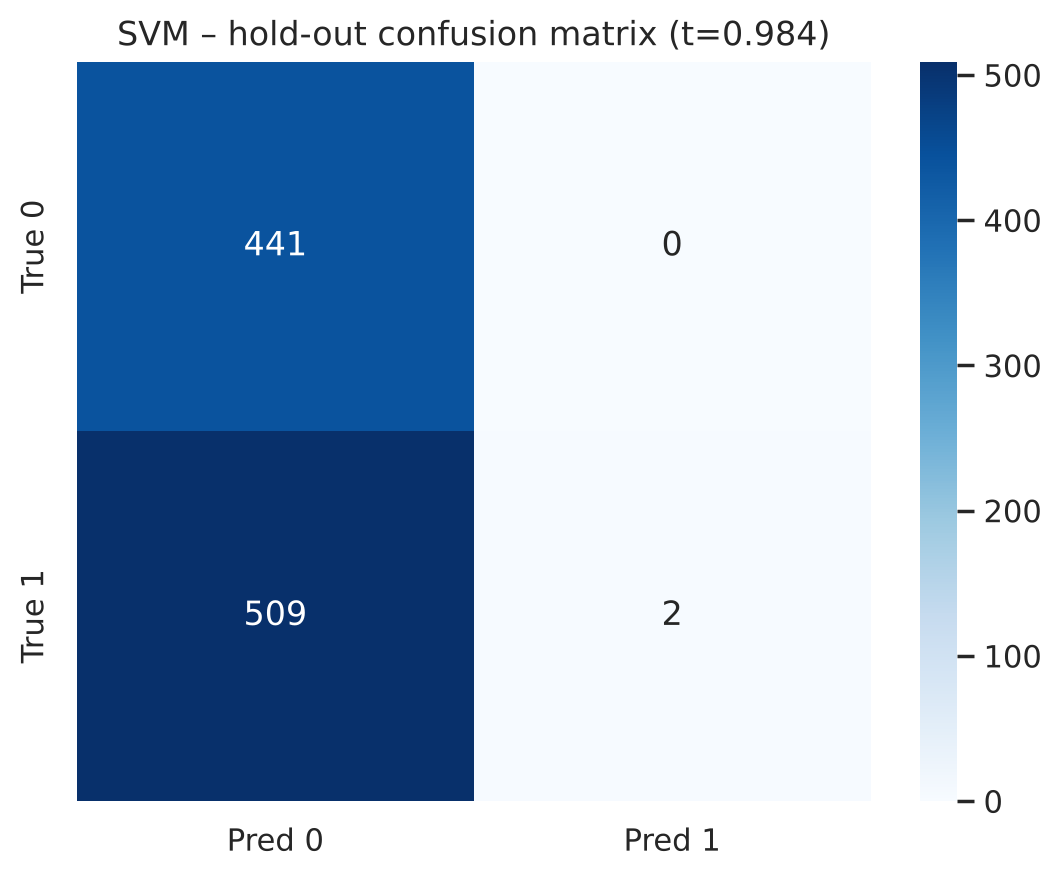

In [31]:
cm = confusion_matrix(y_hold, pred_hold, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
plt.title(f'{MODEL_NAME} – hold-out confusion matrix (t={THRESHOLD:.3f})'); plt.show()

In [32]:
# The same model at the default 0.5 threshold, for contrast
pred_05 = (p_hold >= 0.5).astype(int)
for name, pred in {'t=0.5': pred_05, f't={THRESHOLD:.3f}': pred_hold}.items():
    print(f'{name:8s} accuracy={(pred == y_hold).mean():.3f}  cost per person=${cost_per_person(y_hold, pred):,.2f}')

t=0.5    accuracy=0.778  cost per person=$2,226.79
t=0.984  accuracy=0.465  cost per person=$160.40


## 10. Explaining the model

### 10.2 Permutation importance on the hold-out set
Model-agnostic: how much hold-out log loss gets worse when one original feature is shuffled.

In [33]:
perm = permutation_importance(dev_model, X_hold, y_hold, scoring='neg_log_loss',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

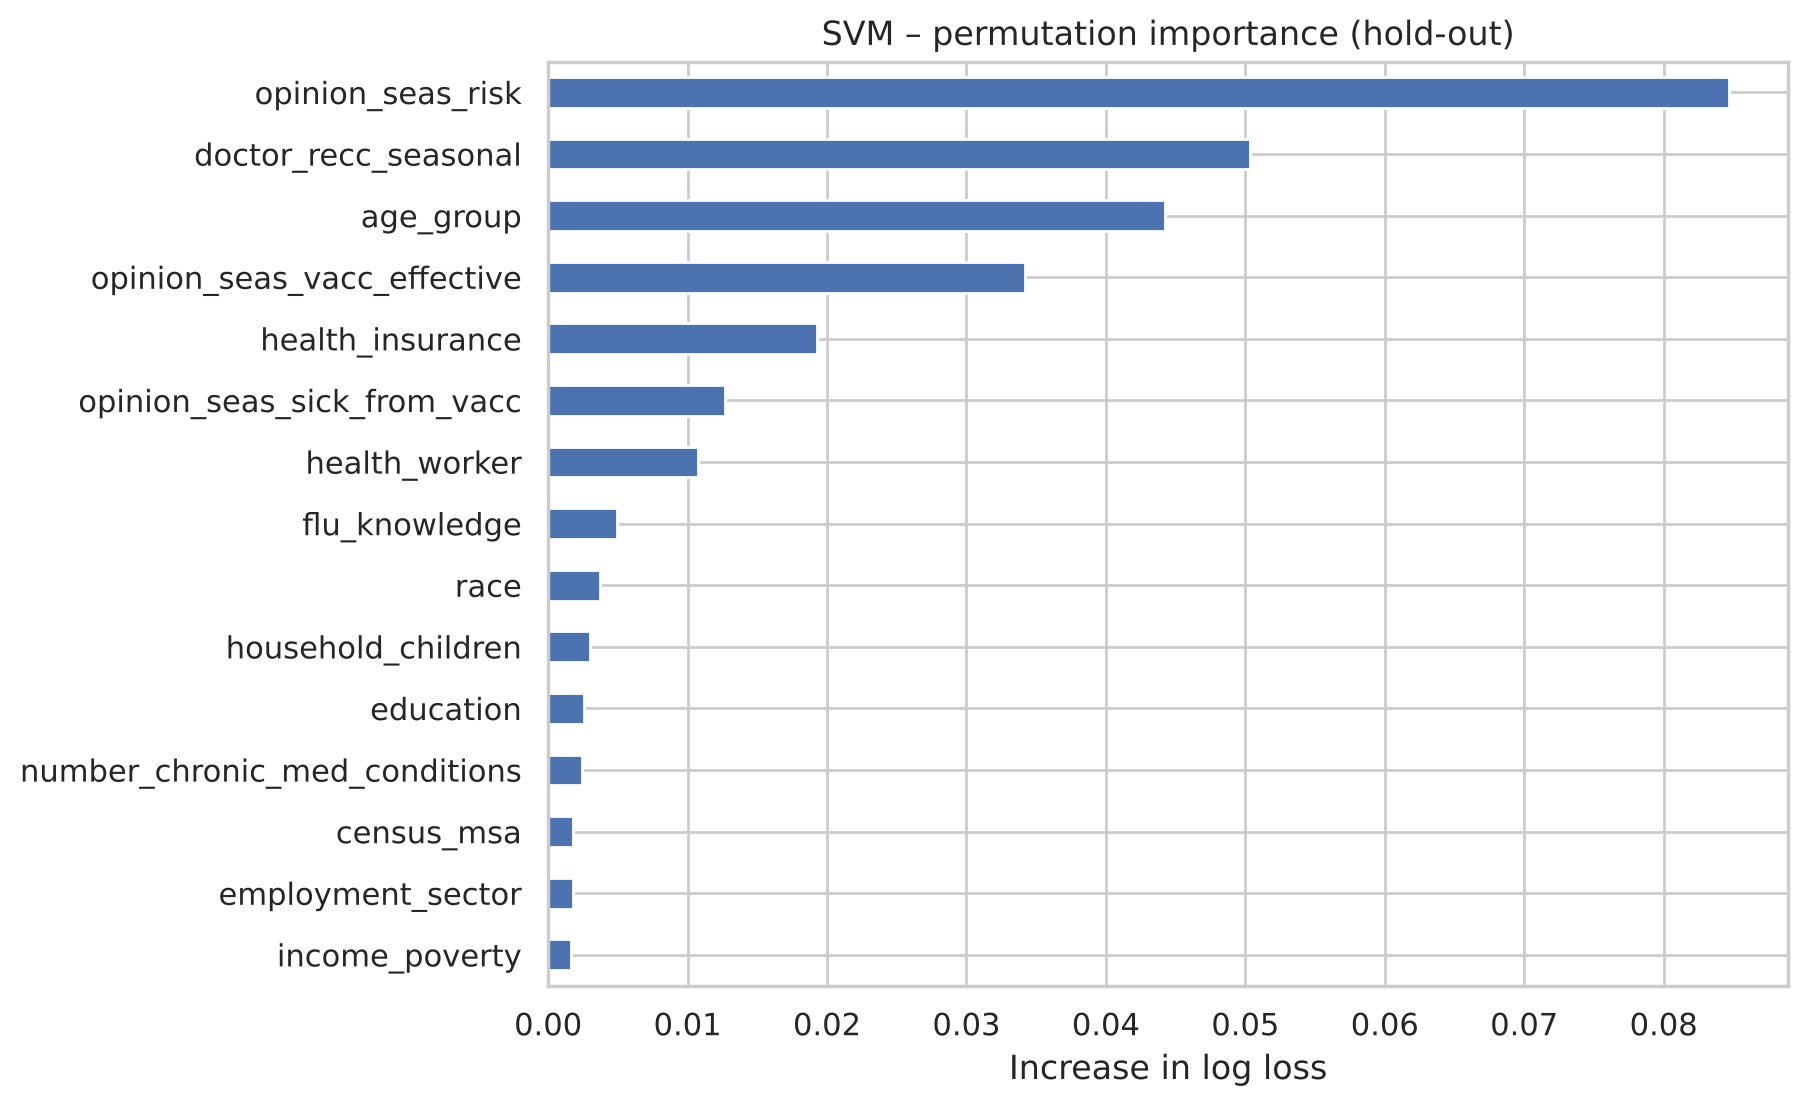

In [34]:
perm_imp.tail(15).plot.barh(figsize=(8, 6), color='#4c72b0')
plt.title(f'{MODEL_NAME} – permutation importance (hold-out)'); plt.xlabel('Increase in log loss')
plt.show()

### Summary of findings – SVM
- **Pre-processing:** Option B (missing-aware) gives the better log loss.
- **Tuning:** `C = 3`, `gamma = 0.003`. The small gamma gives a smooth, nearly linear boundary.
- **Cost:** it flags 7 out-of-fold respondents, all truly vaccinated. It saves about **\$0.63 per person** on average and beats or matches the baseline on every fold.
- **Hold-out:** **\$160.40 per person, the cheapest of the five on the hold-out set** (2 correct "vaccinated" calls).
- **Drivers:** perceived risk, doctor recommendation, age and vaccine effectiveness, matching the other models.

## 11. Save results and test predictions
- `results/<model>_results.json` holds the numbers used by `06_Final_Cost_Comparison`.
- `results/<model>_holdout_proba.csv` holds hold-out probabilities (used for the cost sensitivity analysis).
- `results/<model>_test_predictions.csv` holds test-set predictions from the model refitted on **all** labelled data.

**Upload the `results` folder to the team GitHub repo together with this notebook.**

In [35]:
os.makedirs('results', exist_ok=True)
results = {
    'model': MODEL_NAME,
    'preprocessing': BEST_PREP_NAME,
    'best_params': {k: str(v) for k, v in search.best_params_.items()},
    'cv_log_loss': float(-search.best_score_),
    'rcv_cost_pp_folds': rcv['cost_pp'].round(4).tolist(),
    'rcv_cost_pp_mean': float(rcv['cost_pp'].mean()),
    'rcv_cost_pp_std': float(rcv['cost_pp'].std()),
    'rcv_auc_mean': float(rcv['auc'].mean()),
    'holdout_cost_pp': float(cost_per_person(y_hold, pred_hold)),
    'holdout_cost_pp_t05': float(cost_per_person(y_hold, pred_05)),
    'holdout_auc': float(roc_auc_score(y_hold, p_hold)),
}

In [36]:
with open(f'results/{MODEL_NAME}_results.json', 'w') as f:
    json.dump(results, f, indent=2)
pd.DataFrame({'p': p_hold}, index=X_hold.index).to_csv(f'results/{MODEL_NAME}_holdout_proba.csv')

In [37]:
# Refit on all labelled data (development + hold-out) and predict the test set
final_model = clone(tuned_model).fit(X, y)
p_test = final_model.predict_proba(test[FEATURES])[:, 1]
sub = pd.DataFrame({'respondent_id': test['respondent_id'], TARGET: (p_test >= THRESHOLD).astype(int)})
sub.to_csv(f'results/{MODEL_NAME}_test_predictions.csv', index=False)
print(f'Test respondents predicted as vaccinated: {sub[TARGET].sum()}')

Test respondents predicted as vaccinated: 14


In [38]:
# Colab: download the results folder as a zip to upload to GitHub
try:
    from google.colab import files
    import shutil
    shutil.make_archive(f'{MODEL_NAME}_results', 'zip', 'results')
    files.download(f'{MODEL_NAME}_results.zip')
except ImportError:
    print(os.listdir('results'))

['RandomForest_test_predictions.csv', 'RandomForest_results.json', 'LogReg_results.json', 'ExtraTrees_test_predictions.csv', 'NeuralNet_test_predictions.csv', 'SVM_holdout_proba.csv', 'SVM_results.json', 'LogReg_test_predictions.csv', 'NeuralNet_results.json', 'RandomForest_holdout_proba.csv', 'NeuralNet_holdout_proba.csv', 'ExtraTrees_results.json', 'SVM_test_predictions.csv', 'ExtraTrees_holdout_proba.csv', 'LogReg_holdout_proba.csv']
